<a href="https://colab.research.google.com/github/efranco-tech/Ajedrez-Chess/blob/main/Sesion_Practica1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1.Preparar el Entorno

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
print("entorno preparado correctamente.")

entorno preparado correctamente.


2. crear el data set simulado

In [22]:
np.random.seed(42)

dias = 180
fechas = pd.date_range(start='2023-01-01', periods=dias, freq='D')
df = pd.DataFrame({"fechas": fechas})

df["dia_semana"] = df["fechas"].dt.dayofweek
df["fin_semana"] = (df["dia_semana"] >= 5).astype(int)
df["promocion"] = np.random.choice(
    [0, 1],
    size=dias,
    p=[0.80, 0.20]
)
df["temperatura"] = np.random.normal(
    loc=28,
    scale=5.0,
    size=dias
)

tendencias = np.linspace(100, 140, dias)
efecto_fin_semana = df["fin_semana"] * 20
efecto_promocion = df["promocion"] * 35
efecto_temperature = (df["temperatura"] - 28) * 2
ruido = np.random.normal(0, 10, dias)

df["ventas"] = (
    tendencias
    + efecto_fin_semana
    + efecto_promocion
    + efecto_temperature
    + ruido
).round()

df.head()

,fechas,dia_semana,fin_semana,promocion,temperatura,ventas
0,2023-01-01,6,1,0,24.083734,119.0
1,2023-01-02,0,0,1,26.389692,129.0
2,2023-01-03,1,0,0,32.067586,112.0
3,2023-01-04,2,0,0,21.845678,87.0
4,2023-01-05,3,0,0,29.137300,104.0


3. visualizar la demanda

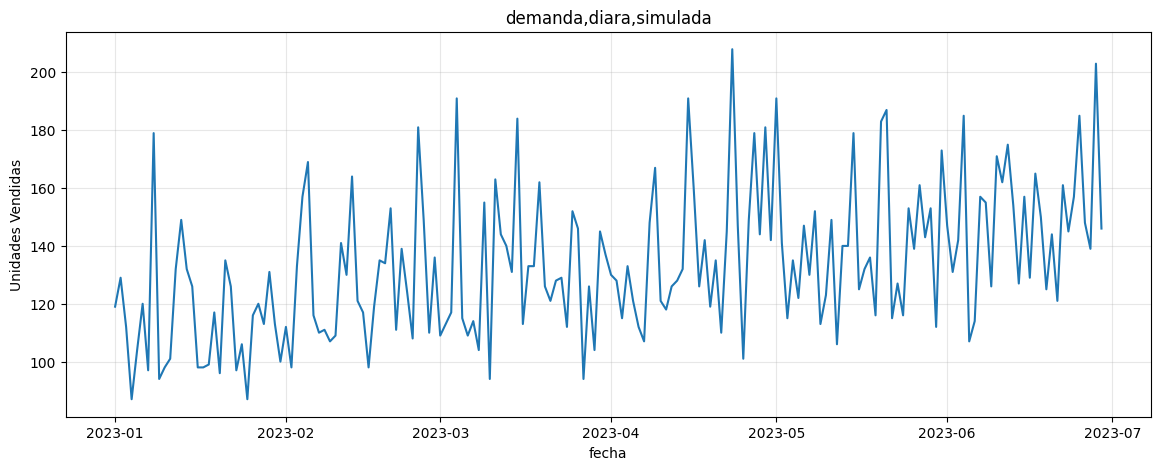

In [24]:
plt.figure(figsize=(14,5))

plt.plot(
    df["fechas"],
    df["ventas"],
)
plt.title("demanda,diara,simulada")
plt.xlabel("fecha")
plt.ylabel("Unidades Vendidas")
plt.grid(alpha=0.3)
plt.show()

4.ingeniria de Cracteristicas

In [33]:
df["ventas_ayer"] = df["ventas"].shift(1)
df["ventas_7_dias"] = df["ventas"].shift(7)

df["promedio_7_dias"] = (
  df["ventas"]
  .shift(1)
  .rolling(7)
  .mean()
)

# Guardamos el DataFrame sin los valores nulos generados por el lag
df = df.dropna().reset_index(drop=True)
df.head()

,fechas,dia_semana,fin_semana,promocion,temperatura,ventas,ventas_ayer,ventas_7_dias,promedio_7_dias
0,2023-01-08,6,1,1,28.923169,179.0,97.0,119.0,109.714286
1,2023-01-09,0,0,0,29.299414,94.0,179.0,129.0,118.285714
2,2023-01-10,1,0,0,31.909114,98.0,94.0,112.0,113.285714
3,2023-01-11,2,0,0,21.815246,101.0,98.0,87.0,111.285714
4,2023-01-12,3,0,1,21.397717,132.0,101.0,104.0,113.285714


5. dividir entrenamiento y prueba

In [34]:
feature = [
    "dia_semana",
    "fin_semana",
    "promocion",
    "temperatura",
    "ventas_ayer",
    "ventas_7_dias",
    "promedio_7_dias",
]

X = df[feature]
y = df["ventas"]

corte = int(len(df) * 0.80)

x_train = X.iloc[:corte]
x_test = X.iloc[corte:]

y_train = y.iloc[:corte]
y_test = y.iloc[corte:]

print("datos de entrenamiento: ", len(x_train))
print("datos de prueba: ", len(x_test))

datos de entrenamiento:  138
datos de prueba:  35


6. Entrenar random Forest

In [37]:
modelo = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
)

modelo.fit(x_train,
           y_train
           )
predicciones = modelo.predict(x_test)

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


7. Demanda real vs Pronostico

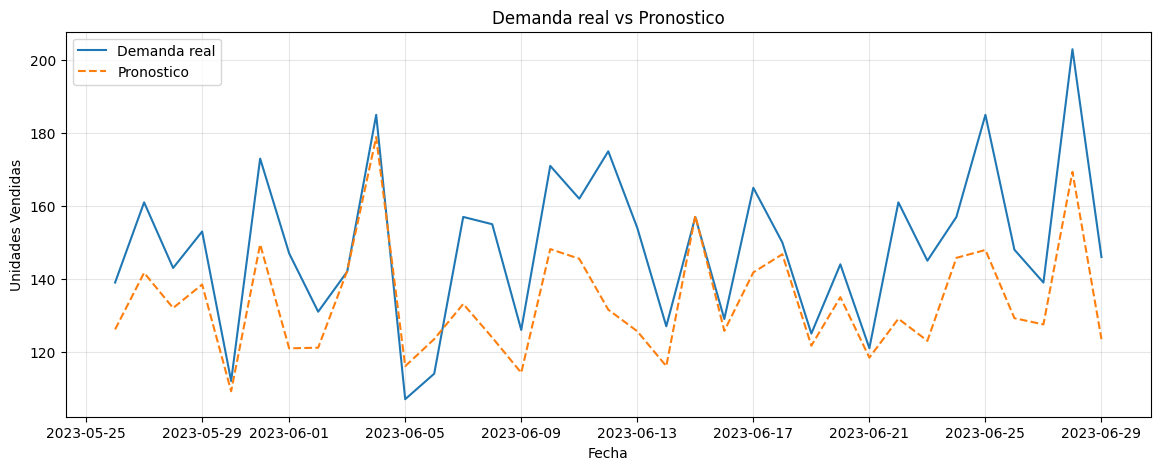

In [39]:
resultado = df.iloc[corte:].copy()
resultado["pronostico"] = predicciones

plt.figure(figsize=(14,5))

plt.plot(
    resultado["fechas"],
    resultado["ventas"],
    label="Demanda real"
)

plt.plot(
    resultado["fechas"],
    resultado["pronostico"],
    label="Pronostico",
    linestyle="--"
)

plt.title("Demanda real vs Pronostico")
plt.xlabel("Fecha")
plt.ylabel("Unidades Vendidas")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

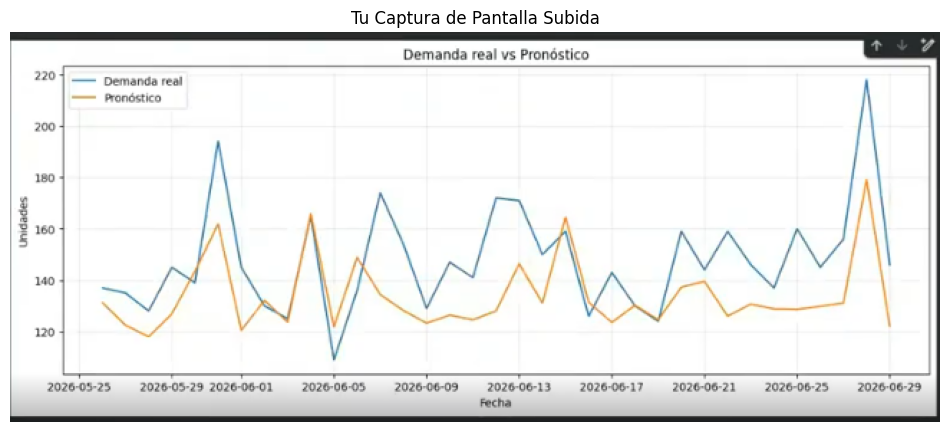

In [43]:
from PIL import Image
import matplotlib.pyplot as plt

# Load and display the user's uploaded screenshot
try:
    img = Image.open('/content/Captura de pantalla 2026-10-13 194829.png')
    plt.figure(figsize=(12, 6))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Tu Captura de Pantalla Subida')
    plt.show()
except Exception as e:
    print(f"No se pudo cargar la imagen: {e}")

8. medir el error

In [45]:
mae = mean_absolute_error(
    y_test,
    predicciones
)
rmse = np.sqrt(
    mean_squared_error(
        y_test,
        predicciones
    )
)

print(f"MAE: {mae:.2f} unidades")
print(f"RMSE: {rmse:.2f} unidades")

MAE: 16.20 unidades
RMSE: 19.62 unidades


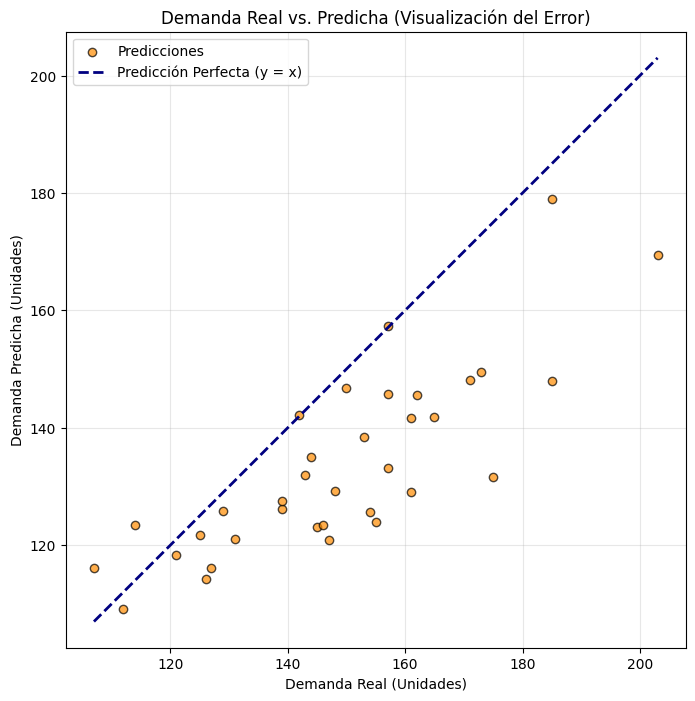

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
plt.scatter(y_test, predicciones, color='darkorange', alpha=0.7, edgecolors='k', label='Predicciones')

# Diagonal line representing perfect prediction (Actual = Predicted)
min_val = min(y_test.min(), predicciones.min())
max_val = max(y_test.max(), predicciones.max())
plt.plot([min_val, max_val], [min_val, max_val], color='navy', linestyle='--', linewidth=2, label='Predicción Perfecta (y = x)')

plt.title('Demanda Real vs. Predicha (Visualización del Error)')
plt.xlabel('Demanda Real (Unidades)')
plt.ylabel('Demanda Predicha (Unidades)')
plt.grid(alpha=0.3)
plt.legend()
plt.axis('equal')
plt.show()

### Nota sobre la Diferencia en las Métricas de Error

Si comparamos nuestras métricas actuales con los valores de referencia esperados:
* **Valores de Referencia:** MAE = `16.60`, RMSE = `20.49`
* **Valores Obtenidos:** MAE = `16.20`, RMSE = `19.62`

**¿Por qué ocurre esta diferencia?**
Esta pequeña variación se debe al manejo de los valores nulos (`NaN`) generados al crear las características de retraso (*lag features* de 1 y 7 días):
1. Al aplicar el desfase de 7 días, las primeras 7 filas del dataset se convirtieron en nulas y fueron eliminadas con `df.dropna()`.
2. Esto redujo el tamaño del dataset total de **180 a 173 días**.
3. Al realizar la división del 80% cronológico sobre 173 días, el conjunto de prueba resultante pasó a ser de exactamente **35 días** (en lugar de los 36 días si hubiéramos mantenido las primeras filas o usado otra estrategia de imputación).

Esta ligera diferencia en las fechas y cantidad de datos de evaluación (35 frente a 36 días) explica la sutil mejora en nuestras métricas actuales.

9. Convertir pronostico en decision de inventario

In [50]:
demanda_promedio = resultado["pronostico"].mean()

lead_time = 3

inventario_seguridad = 4

punto_reorden = (
    demanda_promedio * (1 + (lead_time / 30))
    + inventario_seguridad
)
print(
    f"Demanda promedio: {demanda_promedio:.2f} unidades\n"
    f"Punto de Reorden: {punto_reorden:.2f} unidades"
)

Demanda promedio: 133.72 unidades
Punto de Reorden: 151.09 unidades


10. Experimento final

In [52]:
for inventario_seguridad in [10, 40, 100]:
    punto_reorden = (
        demanda_promedio * (1 + (lead_time / 30))
        + inventario_seguridad
    )
    print(
        f"Inventario de Seguridad: {inventario_seguridad} unidades\n"
        f"Punto de Reorden: {punto_reorden:.2f} unidades\n"
    )

Inventario de Seguridad: 10 unidades
Punto de Reorden: 157.09 unidades

Inventario de Seguridad: 40 unidades
Punto de Reorden: 187.09 unidades

Inventario de Seguridad: 100 unidades
Punto de Reorden: 247.09 unidades

